# A evolução do shift-share: de Dunn (1960) a Nazara-Hewings (2004)

Este notebook percorre, em ordem cronológica, as variantes de análise
shift-share implementadas em `ssa_models.py`, aplicadas a uma economia
artificial em que os efeitos verdadeiros são conhecidos. Cada seção apresenta a
fórmula da nova versão e o que ela muda em relação à anterior, aplica o método
aos mesmos dados e compara o resultado com a verdade. As notas de cada método
vão sendo acumuladas num placar, discutido na seção 11.

O texto foi escrito para alunos de graduação em economia. As seções 4 e 8 usam
noções de regressão por mínimos quadrados; o resto exige só a identidade básica
do shift-share, que a seção 1 apresenta do zero.

Os valores abaixo ficam fixos em todas as seções:

| parâmetro | valor | significado |
|---|---|---|
| `SEED` | 42 | semente do processo gerador (`ssa_dgp.generate_dataset`) |
| `RHO_ESPACIAL` | 0,5 | autocorrelação espacial da vantagem regional (SAR na contiguidade real das UFs) |
| `UF_FOCO` | PI | estado usado nos exemplos numéricos detalhados |

Para trocar o estado em foco ou a semente, altere a célula de configuração e
rode o notebook inteiro de novo. Os comentários escritos entre as células se
referem a `SEED = 42` e `UF_FOCO = "PI"`.

| § | ano | método | o que introduz |
|---|---|---|---|
| 0 | | Metodologia da simulação | a economia artificial e a verdade conhecida |
| 1 | 1960 | Dunn clássico | identidade nacional + estrutural + competitivo |
| 2 | 1959 / 1969 | Pesos de Fuchs e Stilwell | sensibilidade ao ano de ponderação |
| 3 | 1972 | Esteban-Marquillas | emprego homotético e efeito alocação |
| 4 | 1978 / 1984 | Berzeg (ANOVA) | versão estocástica, com erro-padrão |
| 5 | 1984 | Arcelus (Modelo I) | divide nacional e estrutural em esperado/diferencial |
| 6 | 1988 | Barff-Knight (dinâmico) | cálculo ano a ano |
| 7 | extensão | Esteban-Marquillas dinâmico | homotético + ano a ano |
| 8 | 1976 / 1991 | Regressão análoga completa (Buck-Atkins; Patterson) | efeitos fixos com restrição ponderada |
| 9 | 2004 | Nazara-Hewings (espacial) | vizinhança como referência |
| 10 | extensão | Nazara-Hewings dinâmico | espacial + ano a ano |
| 11 | | Síntese | placar e comparação com o Monte Carlo |

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter

import ssa_models as M
from brazil_geo import ADJACENCY, morans_i
from run_comparison import score, significance_diagnostics
from ssa_dgp import generate_dataset

# ---- valores fixos ---------------------------------------------------------
SEED = 42
RHO_ESPACIAL = 0.5
UF_FOCO = "PI"


def br(x, casas=3):
    # Formata números no padrão brasileiro: 1.234,567
    return f"{x:,.{casas}f}".replace(",", "X").replace(".", ",").replace("X", ".")


pd.set_option("display.float_format", br)
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.alpha": 0.3,
        "font.size": 10,
    }
)
AZUL, LARANJA, AQUA, TINTA = "#2a78d6", "#eb6834", "#1baf7a", "#52514e"

## 0. Metodologia: como a simulação foi construída

### Por que usar dados simulados

Com dados reais de emprego, os efeitos nacional, estrutural e competitivo nunca
são observados. Cada método de shift-share entrega a sua decomposição, e não há
como saber qual delas está mais perto da realidade.

A simulação contorna o problema invertendo a ordem do trabalho. Primeiro
escolhemos os efeitos verdadeiros; depois geramos o emprego que eles produzem;
por fim aplicamos cada método aos dados gerados e comparamos o que ele encontra
com o que colocamos lá. É o raciocínio de um experimento de Monte Carlo em
econometria, em que se sorteiam dados a partir de um $\beta$ conhecido para ver
se o estimador o recupera. O código está em `ssa_dgp.py` (processo gerador) e
`brazil_geo.py` (geografia).

### A economia artificial

A economia tem 27 regiões com as siglas e as fronteiras terrestres das UFs
brasileiras, 5 setores (agropecuária, indústria, construção, comércio e serviços;
no código, `Agro`, `Industry`, `Construction`, `Commerce` e `Services`) e 10 anos
de crescimento, ou seja, 11 observações anuais de emprego ($t = 0, \dots, 10$).
Tamanhos e estruturas setoriais são sorteados: o "PI" da simulação tem os vizinhos
do Piauí real, mas o emprego dele é inventado.

### Passo 1: as taxas de crescimento verdadeiras

O ponto central do desenho é escrever a taxa de crescimento do emprego no setor
$i$ da região $r$, no ano $t$, como a soma de quatro parcelas:

$$
g_{rit} = \underbrace{n_t}_{\text{nacional}} + \underbrace{m_{it}}_{\text{estrutural}}
        + \underbrace{c_{ri}}_{\text{competitivo}} + \underbrace{\varepsilon_{rit}}_{\text{ruído}},
\qquad c_{ri} = \bar c_r + d_{ri} .
$$

Os efeitos ficam, assim, no espaço das taxas de crescimento, que é onde todas as
variantes de shift-share supõem que eles estão.

| parcela | o que representa | como é sorteada |
|---|---|---|
| $n_t$ | crescimento do país no ano $t$ | $N(0{,}025;\ 0{,}012^2)$: em média 2,5% ao ano |
| $m_{it}$ | quanto o setor $i$ cresce acima ou abaixo do país | parte fixa do setor $\sim N(0;\ 0{,}020^2)$ mais oscilação anual $\sim N(0;\ 0{,}004^2)$, com média zero entre os setores em cada ano |
| $\bar c_r$ | vantagem da região, comum a todos os seus setores | processo espacial do passo 2, desvio-padrão 0,015 |
| $d_{ri}$ | vantagem da região específica do setor | $N(0;\ 0{,}010^2)$, com média zero dentro de cada região |
| $\varepsilon_{rit}$ | choque idiossincrático | $N(0;\ 0{,}006^2)$, independente entre regiões, setores e anos |

Um exemplo de leitura: se num ano o país cresce 2,5%, o comércio cresce 1 ponto
percentual acima do país e o Piauí tem desvantagem de 0,5 ponto no comércio, o
emprego no comércio piauiense cresce cerca de 3% naquele ano, mais o choque
$\varepsilon$. Nenhum método consegue recuperar o choque; ele é o "erro" do
experimento.

A vantagem competitiva $c_{ri}$ não muda com o tempo. Cada região mantém a mesma
vantagem em cada setor ao longo dos dez anos.

### Passo 2: a dependência espacial

A vantagem comum $\bar c_r$ é gerada por um processo espacial autorregressivo
(SAR). A matriz de vizinhança $W$ tem $w_{rk} = 1/(\text{número de vizinhos de } r)$
quando $r$ e $k$ fazem fronteira, e zero caso contrário. O Piauí tem cinco
vizinhos (MA, CE, PE, BA e TO), cada um com peso 1/5. O processo é

$$
\bar c_r = \rho \sum_k w_{rk}\,\bar c_k + u_r, \qquad u_r \sim N(0;\ 0{,}015^2),
\qquad\text{ou, em forma matricial,}\qquad \bar c = (I-\rho W)^{-1}u .
$$

Com $\rho = 0{,}5$, a vantagem de cada estado é metade da média dos vizinhos mais
um componente próprio $u_r$, e estados vizinhos tendem a ter vantagens parecidas.
Depois do sorteio, $\bar c$ é centrado em zero e reescalado para desvio-padrão
0,015, de modo que a dispersão das vantagens não dependa de $\rho$.

A dependência espacial é o que dá sentido ao modelo de Nazara-Hewings (seção 9).
O cenário com $\rho = 0$ do Monte Carlo funciona como controle.

### Passo 3: o emprego inicial e a estrutura setorial

O emprego total de cada região no ano 0 vem de uma lognormal (média 12 e
desvio-padrão 0,8 no logaritmo), o que dá uma mediana de cerca de 163 mil empregos
e estados de tamanhos bem diferentes. A divisão desse emprego entre os setores vem
de uma distribuição de Dirichlet, a distribuição usual para sortear participações
que somam 1.

Para testar o efeito alocação de Esteban-Marquillas (seção 3), as 27 regiões são
divididas por sorteio em três grupos de nove:

- `well_allocated`: a estrutura inicial pende para os setores em que a região tem vantagem ($d_{ri} > 0$);
- `mis_allocated`: pende para os setores em que ela tem desvantagem;
- `neutral`: as participações são sorteadas sem relação com $d_{ri}$.

Tecnicamente, o parâmetro da Dirichlet do setor $i$ é
$8 \pm 6\, d_{ri}/\max_j |d_{rj}|$, com piso de 0,5, usando o sinal $+$ no primeiro
grupo e $-$ no segundo. Nos neutros ele vale 8 para todos os setores.

### Passo 4: a trajetória do emprego

Com as taxas e o emprego inicial, o emprego evolui um ano por vez:

$$
E_{ri,t+1} = E_{rit}\,(1 + g_{rit}) .
$$

### Passo 5: a decomposição verdadeira, em empregos

Os métodos de shift-share expressam os efeitos em número de empregos, então a
verdade precisa estar na mesma unidade. Como o crescimento é aplicado ano a ano,
a variação do emprego de cada região se decompõe exatamente em

$$
\Delta E_r = \underbrace{\sum_{i,t} E_{rit}\,n_t}_{\text{nacional}}
           + \underbrace{\sum_{i,t} E_{rit}\,m_{it}}_{\text{estrutural}}
           + \underbrace{\sum_{i,t} E_{rit}\,c_{ri}}_{\text{competitivo}}
           + \underbrace{\sum_{i,t} E_{rit}\,\varepsilon_{rit}}_{\text{ruído}} .
$$

Cada parcela soma, ao longo de setores e anos, o emprego do início do ano vezes a
taxa correspondente. O código confere que as quatro parcelas reproduzem
$\Delta E_r$ até a precisão da máquina.

Algumas seções precisam de verdades adicionais, calculadas do mesmo jeito:

- para Esteban-Marquillas e Arcelus, o emprego de cada ano é dividido em emprego
  homotético $\hat E_{rit}$ (o total da região repartido segundo a estrutura
  nacional daquele ano) e no desvio $E_{rit} - \hat E_{rit}$. O competitivo
  homotético verdadeiro é $\sum_{i,t} \hat E_{rit}\,c_{ri}$ e a alocação
  verdadeira é $\sum_{i,t} (E_{rit} - \hat E_{rit})\,c_{ri}$;
- para Nazara-Hewings, a taxa $c_{ri}$ é dividida na média dos vizinhos,
  $(Wc)_{ri}$, e na diferença $c_{ri} - (Wc)_{ri}$. Multiplicando cada parte por
  $E_{rit}$ e somando, obtêm-se a vizinhança e o próprio líquido verdadeiros.

### Passo 6: como medir o acerto

Para cada método, o efeito competitivo estimado das 27 regiões, $x_r$, é
comparado com o verdadeiro, $y_r$, por quatro medidas:

| medida | definição | pergunta que responde |
|---|---|---|
| Pearson | $\text{corr}(x, y)$ | estimativa e verdade andam juntas? |
| Spearman | correlação entre as posições (postos) de $x$ e de $y$ | o método ordena as regiões corretamente? |
| nRMSE | $\sqrt{\tfrac{1}{27}\sum_r (x_r-y_r)^2}\ \big/\ \text{dp}(y)$ | qual o tamanho do erro? Abaixo de 1, o método erra menos que atribuir a média a todas as regiões |
| acerto de sinal | fração de regiões com $\text{sinal}(x_r) = \text{sinal}(y_r)$ | o método diz corretamente quem ganha e quem perde? |

Um método pode ter correlação alta e nRMSE ruim: basta ordenar bem as regiões e
errar a escala do efeito.

### Uma semente e muitas sementes

Todos os sorteios dependem da semente do gerador de números aleatórios. Aqui a
semente é fixa (`SEED = 42`), e por isso os mesmos dados atravessam o notebook
inteiro. Uma semente, porém, é uma única realização do acaso. O script
`run_comparison.py` repete o experimento com 50 sementes em três cenários, e a
seção 11 compara os dois resultados:

| cenário | parâmetros |
|---|---|
| benigno | $\rho = 0{,}5$ e os valores do passo 1 |
| estresse | $\rho = 0{,}5$; desvio-padrão de $n_t$ = 0,035; parte fixa de $m_{it}$ = 0,035; oscilação anual de $m_{it}$ = 0,020; $\varepsilon$ = 0,015 |
| sem espaço | $\rho = 0$ e os valores do passo 1 |

O cenário de estresse reproduz as condições (ciclo nacional volátil, choques
setoriais fortes, mais ruído) em que, segundo Barff e Knight (1988), os métodos estáticos
de dois pontos deixam de funcionar.

### Limites do experimento

A vantagem competitiva é constante no tempo e os choques são independentes, o que
facilita a vida de todos os métodos. Em dados reais os efeitos competitivos mudam
de um período para outro, então o desempenho medido aqui é um teto. A simulação
também não diz nada sobre o uso do shift-share para previsão ou para inferência
causal.

### A simulação com a semente fixa

A célula abaixo roda o processo gerador e mostra os parâmetros sorteados: as
taxas nacional e setoriais de cada ano e a vantagem comum $\bar c_r$ de cada UF.

In [2]:
data = generate_dataset(seed=SEED, rho_space=RHO_ESPACIAL)
E, regions, sectors, W = data["E"], data["regions"], data["sectors"], data["W"]
truth = data["truth"]
T = data["n_years"]
r_foco = regions.index(UF_FOCO)
verdade_foco = truth.set_index("region").loc[UF_FOCO]

print(
    f"Painel: {E.shape[0]} UFs × {E.shape[1]} setores × {E.shape[2]} observações "
    f"anuais (t = 0..{T})"
)
print(
    "Regiões por grupo de alocação:", pd.Series(data["groups"]).value_counts().to_dict()
)

anos = pd.Index(range(1, T + 1), name="ano")
taxas = pd.DataFrame(
    np.vstack([data["n_t"], data["m_it"]]),
    columns=anos,
    index=["nacional, n_t"] + [f"setor {s}, m_it" for s in sectors],
)
display(
    Markdown(
        "**Taxas sorteadas por ano** (nacional e desvio de cada setor em relação ao país)"
    )
)
display(taxas.style.format(decimal=",", thousands=".", formatter="{:+.2%}"))

Painel: 27 UFs × 5 setores × 11 observações anuais (t = 0..10)
Regiões por grupo de alocação: {'well_allocated': 9, 'mis_allocated': 9, 'neutral': 9}


**Taxas sorteadas por ano** (nacional e desvio de cada setor em relação ao país)

ano,1,2,3,4,5,6,7,8,9,10
"nacional, n_t","+2,87%","+1,25%","+3,40%","+3,63%","+0,16%","+0,94%","+2,65%","+2,12%","+2,48%","+1,48%"
"setor Agro, m_it","+0,13%","+0,47%","+0,03%","+0,76%","+0,25%","+0,25%","+0,18%","+1,02%","+0,41%","+0,22%"
"setor Industry, m_it","+0,13%","+0,33%","+0,35%","+0,37%","+0,24%","+0,98%","+0,09%","+0,12%","-0,06%","+0,43%"
"setor Construction, m_it","-0,70%","-1,35%","-1,55%","-1,55%","-1,10%","-1,00%","-0,96%","-1,36%","-1,06%","-1,19%"
"setor Commerce, m_it","+1,05%","+1,17%","+0,99%","+1,18%","+0,79%","+0,94%","+1,20%","+0,44%","+0,84%","+0,70%"
"setor Services, m_it","-0,61%","-0,61%","+0,18%","-0,76%","-0,17%","-1,17%","-0,51%","-0,23%","-0,12%","-0,15%"


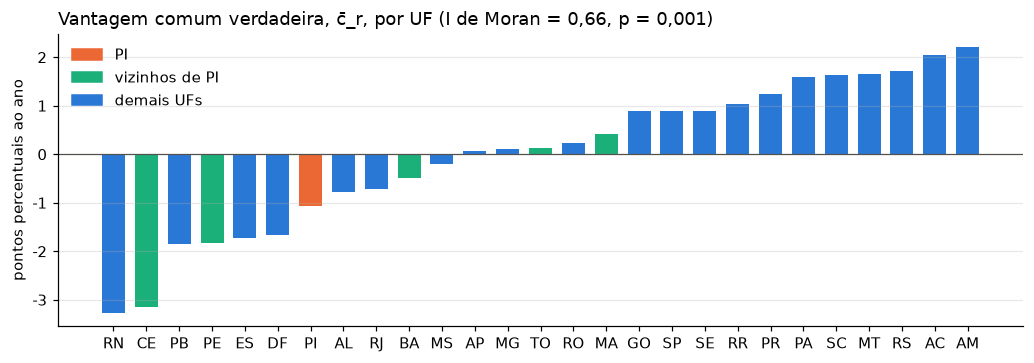

In [3]:
cbar = pd.Series(data["c_bar"], index=regions).sort_values()
vizinhos = ADJACENCY[UF_FOCO]
cores = [
    LARANJA if uf == UF_FOCO else AQUA if uf in vizinhos else AZUL for uf in cbar.index
]
I_moran, p_moran = morans_i(data["c_bar"], W)

fig, ax = plt.subplots(figsize=(9.5, 3.4))
ax.bar(cbar.index, cbar.values * 100, color=cores, width=0.7)
ax.axhline(0, color=TINTA, lw=0.8)
ax.set_ylabel("pontos percentuais ao ano")
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: br(v, 0)))
ax.set_title(
    f"Vantagem comum verdadeira, c̄_r, por UF (I de Moran = {br(I_moran, 2)}, "
    f"p = {br(p_moran)})",
    loc="left",
)
ax.grid(axis="x", visible=False)
ax.legend(
    handles=[
        Patch(color=LARANJA, label=UF_FOCO),
        Patch(color=AQUA, label=f"vizinhos de {UF_FOCO}"),
        Patch(color=AZUL, label="demais UFs"),
    ],
    frameon=False,
    loc="upper left",
)
plt.tight_layout()
plt.show()

O I de Moran mede a autocorrelação espacial: perto de zero quando vizinhos não
se parecem, positivo quando estados vizinhos têm valores parecidos. O valor
positivo e significativo confirma que o processo SAR do passo 2 produziu
agrupamentos espaciais de vantagem.

Para o estado em foco, a tabela abaixo traz a decomposição verdadeira que os
métodos tentarão recuperar.

In [4]:
print(
    f"{UF_FOCO}: grupo de alocação = {verdade_foco['group']}, "
    f"c̄ verdadeiro = {br(verdade_foco['c_bar'], 4)} ao ano, "
    f"vizinhos = {', '.join(ADJACENCY[UF_FOCO])}"
)

cols = [
    "delta_E",
    "true_national",
    "true_mix",
    "true_comp",
    "true_noise",
    "true_comp_homothetic",
    "true_alloc",
    "true_neigh",
    "true_own_net",
]
nomes = [
    "ΔE observado",
    "nacional",
    "estrutural",
    "competitivo",
    "ruído",
    "competitivo homotético",
    "alocação",
    "vizinhança",
    "próprio líquido",
]
verdade_tab = verdade_foco[cols].astype(float).rename(dict(zip(cols, nomes)))
display(
    verdade_tab.to_frame(f"verdade ({UF_FOCO})").style.format(
        decimal=",", thousands=".", formatter="{:,.1f}"
    )
)

PI: grupo de alocação = well_allocated, c̄ verdadeiro = -0,0106 ao ano, vizinhos = MA, CE, PE, BA, TO


,verdade (PI)
ΔE observado,"19.222,2"
nacional,"26.969,2"
estrutural,"2.373,6"
competitivo,"-11.704,1"
ruído,"1.583,6"
competitivo homotético,"-12.464,5"
alocação,"760,4"
vizinhança,"-13.482,5"
próprio líquido,"1.778,4"


In [5]:
# Placar: cada seção registra a nota do seu método (idempotente ao reexecutar)
placar = {}
ROTULOS = {
    "pearson": "Pearson",
    "spearman": "Spearman",
    "nrmse": "nRMSE",
    "sign_acc": "acerto de sinal",
}
SIGNIF = {
    "model": "modelo",
    "power_strong_regions": "% sinalizadas (terço forte)",
    "flag_rate_weak_regions": "% sinalizadas (terço fraco)",
    "share_flagged_overall": "% sinalizadas (total)",
}


def registrar(ano, metodo, nome_mc, est, alvo="true_comp"):
    s = score(est, truth, "competitive", alvo)
    linha = {"ano": ano, "método": metodo, "modelo_mc": nome_mc, "alvo": alvo, **s}
    linha["mix_nrmse"] = (
        score(est, truth, "mix", "true_mix")["nrmse"]
        if "mix" in est.columns
        else np.nan
    )
    linha[f"competitivo_{UF_FOCO}"] = est.set_index("region").loc[
        UF_FOCO, "competitive"
    ]
    linha[f"verdade_{UF_FOCO}"] = verdade_foco[alvo]
    placar[metodo] = linha
    return pd.DataFrame([s], index=[metodo]).rename(columns=ROTULOS)


def foco(est, pares):
    # Componentes estimados vs. verdadeiros para UF_FOCO.
    e = est.set_index("region").loc[UF_FOCO]
    linhas = {
        nome: {
            "estimado": e[c_est],
            "verdadeiro": verdade_foco[c_true] if c_true else np.nan,
        }
        for nome, (c_est, c_true) in pares.items()
    }
    df = pd.DataFrame(linhas).T.astype(float)
    df["erro"] = df["estimado"] - df["verdadeiro"]
    return df.style.format(decimal=",", thousands=".", formatter="{:,.1f}", na_rep="—")


PARES_DUNN = {
    "nacional": ("national", "true_national"),
    "estrutural": ("mix", "true_mix"),
    "competitivo": ("competitive", "true_comp"),
    "total explicado": ("total_explained", "delta_E"),
}

Nas seções seguintes, para as 27 UFs, o efeito competitivo estimado é comparado
com o verdadeiro por correlação de Pearson e Spearman, nRMSE (RMSE dividido
pelo desvio-padrão da verdade: abaixo de 1 é melhor que chutar a média) e acerto
de sinal. A tabela do estado em foco mostra os componentes em unidades de emprego.

## 1. Dunn (1960): a identidade clássica

Com apenas dois cortes (ano-base $0$ e ano final $T$), defina
$g_{ri} = E^T_{ri}/E^0_{ri}-1$ (taxa do setor $i$ na região $r$),
$g_i = E^T_{\cdot i}/E^0_{\cdot i}-1$ (taxa nacional do setor) e
$g = E^T_{\cdot\cdot}/E^0_{\cdot\cdot}-1$ (taxa nacional total). Um ponto no lugar de um
índice indica soma: $E_{\cdot i}$ é o emprego do setor $i$ no país inteiro e
$E_{\cdot\cdot}$ o emprego total do país. A variação do emprego da região se
decompõe em

$$
\Delta E_r =
\underbrace{\sum_i E^0_{ri}\, g}_{\text{nacional (NE)}}
+ \underbrace{\sum_i E^0_{ri}\,(g_i - g)}_{\text{estrutural (IM)}}
+ \underbrace{\sum_i E^0_{ri}\,(g_{ri} - g_i)}_{\text{competitivo (CE)}} .
$$

Cada termo responde a uma pergunta. O nacional é quanto a região teria crescido
se todos os seus setores crescessem à taxa do país. O estrutural é o ganho (ou a
perda) por ter uma composição setorial concentrada em setores que crescem mais
(ou menos) no país. O competitivo é o restante: quanto os setores da região
cresceram acima dos mesmos setores no país.

Como $g_{ri}E^0_{ri} = E^T_{ri}-E^0_{ri}$, os três termos somados reproduzem
$\Delta E_r$ exatamente; é uma identidade contábil. Os pesos são o emprego do
ano-base, e só os extremos do período entram no cálculo.

Antes de chamar a função do módulo, vale fazer a conta à mão para o estado em foco, setor a setor:

In [6]:
E0, ET = E[:, :, 0], E[:, :, T]
g_n = ET.sum() / E0.sum() - 1
g_i = ET.sum(0) / E0.sum(0) - 1
g_ri = ET[r_foco] / E0[r_foco] - 1

det = pd.DataFrame(
    {
        "E⁰": E0[r_foco],
        "g_ri": g_ri,
        "g_i": g_i,
        "NE = E⁰·g": E0[r_foco] * g_n,
        "IM = E⁰·(g_i−g)": E0[r_foco] * (g_i - g_n),
        "CE = E⁰·(g_ri−g_i)": E0[r_foco] * (g_ri - g_i),
    },
    index=sectors,
)
det.loc["Total"] = det.sum()
det.loc["Total", ["g_ri", "g_i"]] = np.nan
print(f"g (nacional, {T} anos) = {br(g_n, 4)}")
display(
    det.style.format(
        decimal=",",
        thousands=".",
        formatter={
            "E⁰": "{:,.0f}",
            "g_ri": "{:.4f}",
            "g_i": "{:.4f}",
            "NE = E⁰·g": "{:,.1f}",
            "IM = E⁰·(g_i−g)": "{:,.1f}",
            "CE = E⁰·(g_ri−g_i)": "{:,.1f}",
        },
        na_rep="",
    )
)

g (nacional, 10 anos) = 0,2492


,E⁰,g_ri,g_i,NE = E⁰·g,IM = E⁰·(g_i−g),CE = E⁰·(g_ri−g_i)
Agro,19.943,"0,1139","0,2887","4.970,1","786,8","-3.484,8"
Industry,22.650,"0,0892","0,3310","5.644,8","1.851,8","-5.475,4"
Construction,19.273,"-0,0079","0,0757","4.803,2","-3.343,7","-1.612,5"
Commerce,37.897,"0,3617","0,3924","9.444,6","5.425,0","-1.161,9"
Services,20.697,"0,0664","0,2024","5.158,2","-968,1","-2.815,9"
Total,120.460,,,"30.020,9","3.751,8","-14.550,4"


In [7]:
dunn = M.classic_dunn(E, regions, "base")
assert np.isclose(
    dunn.loc[r_foco, "competitive"], det.loc["Total", "CE = E⁰·(g_ri−g_i)"]
)
display(foco(dunn, PARES_DUNN))
registrar(1960, "Dunn clássico (pesos base)", "Classic Dunn (base wts)", dunn)

,estimado,verdadeiro,erro
nacional,"30.020,9","26.969,2","3.051,8"
estrutural,"3.751,8","2.373,6","1.378,2"
competitivo,"-14.550,4","-11.704,1","-2.846,4"
total explicado,"19.222,2","19.222,2","-0,0"


,Pearson,Spearman,nRMSE,acerto de sinal
Dunn clássico (pesos base),"0,985","0,985","0,231","1,000"


O total explicado bate com o $\Delta E$ observado, como toda identidade. Os
componentes, porém, se afastam da verdade: no PI, o nacional fica superestimado e
o competitivo sai mais negativo que o verdadeiro. Os pesos do ano-base ignoram que
a composição setorial do estado muda ao longo dos dez anos, e a verdade é ponderada
pelo emprego de cada ano.

## 2. A escolha dos pesos: Fuchs (1959) e Stilwell (1969)

A primeira linha de críticas ataca os pesos. A mesma estrutura de Dunn é mantida,
trocando $E^0_{ri}$ por um peso $w_{ri}$:

$$
NE_r = \sum_i w_{ri}\,g,\qquad IM_r = \sum_i w_{ri}(g_i-g),\qquad
CE_r = \sum_i w_{ri}(g_{ri}-g_i)
$$

| variante | peso $w_{ri}$ |
|---|---|
| base (Dunn) | $E^0_{ri}$ |
| terminal (Stilwell) | $E^T_{ri}/(1+g)$ (emprego final deflacionado à escala do ano-base) |
| média (Fuchs) | $\tfrac12\left[E^0_{ri} + E^T_{ri}/(1+g)\right]$ |

Com pesos diferentes do ano-base, a soma dos componentes deixa de reproduzir
$\Delta E_r$ exatamente (Herzog e Olsen, 1977, alertam para essa sensibilidade).

In [8]:
terminal = M.classic_dunn(E, regions, "terminal")
fuchs = M.classic_dunn(E, regions, "average")
display(Markdown("**Pesos terminais (Stilwell)**"))
display(foco(terminal, PARES_DUNN))
display(Markdown("**Pesos médios (Fuchs)**"))
display(foco(fuchs, PARES_DUNN))
pd.concat(
    [
        registrar(
            1969,
            "Dunn, pesos terminais (Stilwell)",
            "Classic Dunn (terminal wts)",
            terminal,
        ),
        registrar(
            1959, "Dunn, pesos médios (Fuchs)", "Classic Dunn (avg wts, Fuchs)", fuchs
        ),
    ]
)

**Pesos terminais (Stilwell)**

,estimado,verdadeiro,erro
nacional,"27.866,6","26.969,2","897,4"
estrutural,"4.748,0","2.373,6","2.374,3"
competitivo,"-12.832,4","-11.704,1","-1.128,3"
total explicado,"19.782,1","19.222,2","559,9"


**Pesos médios (Fuchs)**

,estimado,verdadeiro,erro
nacional,"28.943,8","26.969,2","1.974,6"
estrutural,"4.249,9","2.373,6","1.876,2"
competitivo,"-13.691,4","-11.704,1","-1.987,3"
total explicado,"19.502,2","19.222,2","279,9"


,Pearson,Spearman,nRMSE,acerto de sinal
"Dunn, pesos terminais (Stilwell)","0,988","0,980","0,154","1,000"
"Dunn, pesos médios (Fuchs)","0,991","0,980","0,161","1,000"


In [9]:
# O que se ganha no competitivo se perde em outro lugar: o efeito estrutural
pd.DataFrame(
    {
        m: {
            "nRMSE competitivo": placar[m]["nrmse"],
            "nRMSE estrutural": placar[m]["mix_nrmse"],
        }
        for m in [
            "Dunn clássico (pesos base)",
            "Dunn, pesos terminais (Stilwell)",
            "Dunn, pesos médios (Fuchs)",
        ]
    }
).T

,nRMSE competitivo,nRMSE estrutural
Dunn clássico (pesos base),"0,231","0,413"
"Dunn, pesos terminais (Stilwell)","0,154","0,972"
"Dunn, pesos médios (Fuchs)","0,161","0,599"


Nesta semente os pesos terminais e médios melhoram o competitivo, mas pioram
muito o efeito estrutural, e o total explicado deixa de fechar com $\Delta E$.
A seção 11 mostra que, na média de 50 sementes, a ordem se inverte: os pesos
terminais são os piores para o competitivo. Uma única realização não basta para
ordenar os métodos.

## 3. Esteban-Marquillas (1972): emprego homotético e efeito alocação

O competitivo de Dunn mistura duas coisas: a vantagem do estado em cada setor e o
fato de ele ter muito ou pouco emprego justamente nesses setores. Esteban-Marquillas
separa as duas usando o emprego homotético, o emprego que o estado teria se sua
estrutura setorial fosse igual à nacional:

$$
\hat E_{ri} = E^0_{r\cdot}\,\frac{E^0_{\cdot i}}{E^0_{\cdot\cdot}} .
$$

O competitivo de Dunn se divide em

$$
CE_r = \underbrace{\sum_i \hat E_{ri}\,(g_{ri}-g_i)}_{\text{competitivo homotético } CE^*_r}
     + \underbrace{\sum_i \left(E^0_{ri}-\hat E_{ri}\right)(g_{ri}-g_i)}_{\text{alocação } AE_r} .
$$

$AE_r>0$ quando o estado está especializado ($E>\hat E$) nos setores em que é
competitivo ($g_{ri}>g_i$). O alvo agora é o competitivo homotético verdadeiro
(`true_comp_homothetic`) e a alocação verdadeira (`true_alloc`).

In [10]:
E_hat = M._homothetic(E0)
alo = pd.DataFrame(
    {
        "E⁰": E0[r_foco],
        "Ê (homotético)": E_hat[r_foco],
        "E⁰ − Ê": E0[r_foco] - E_hat[r_foco],
        "g_ri − g_i": g_ri - g_i,
        "CE* = Ê·(g_ri−g_i)": E_hat[r_foco] * (g_ri - g_i),
        "AE = (E⁰−Ê)·(g_ri−g_i)": (E0[r_foco] - E_hat[r_foco]) * (g_ri - g_i),
    },
    index=sectors,
)
alo.loc["Total"] = alo.sum()
alo.loc["Total", "g_ri − g_i"] = np.nan
display(
    alo.style.format(
        decimal=",",
        thousands=".",
        formatter={
            c: ("{:.4f}" if c == "g_ri − g_i" else "{:,.1f}") for c in alo.columns
        },
        na_rep="",
    )
)

em = M.esteban_marquillas(E, regions)
display(
    foco(
        em,
        {
            "nacional": ("national", "true_national"),
            "estrutural": ("mix", "true_mix"),
            "competitivo homotético": ("competitive", "true_comp_homothetic"),
            "alocação": ("allocation", "true_alloc"),
            "total explicado": ("total_explained", "delta_E"),
        },
    )
)
registrar(
    1972,
    "Esteban-Marquillas",
    "Esteban-Marquillas (static)",
    em,
    alvo="true_comp_homothetic",
)

,E⁰,Ê (homotético),E⁰ − Ê,g_ri − g_i,CE* = Ê·(g_ri−g_i),AE = (E⁰−Ê)·(g_ri−g_i)
Agro,"19.942,8","16.957,2","2.985,6","-0,1747","-2.963,1","-521,7"
Industry,"22.650,0","16.824,1","5.825,9","-0,2417","-4.067,0","-1.408,3"
Construction,"19.273,1","30.100,6","-10.827,5","-0,0837","-2.518,4","905,9"
Commerce,"37.896,9","30.665,2","7.231,7","-0,0307","-940,2","-221,7"
Services,"20.697,4","25.913,1","-5.215,7","-0,1361","-3.525,5","709,6"
Total,"120.460,3","120.460,3","0,0",,"-14.014,2","-536,3"


,estimado,verdadeiro,erro
nacional,"30.020,9","26.969,2","3.051,8"
estrutural,"3.751,8","2.373,6","1.378,2"
competitivo homotético,"-14.014,2","-12.464,5","-1.549,7"
alocação,"-536,3","760,4","-1.296,7"
total explicado,"19.222,2","19.222,2","-0,0"


,Pearson,Spearman,nRMSE,acerto de sinal
Esteban-Marquillas,"0,988","0,979","0,201","1,000"


In [11]:
# O efeito alocação "funciona"? Média por grupo do processo gerador
grupo = truth.set_index("region")["group"]
pd.DataFrame(
    {
        "alocação estimada": em.set_index("region")["allocation"],
        "alocação verdadeira": truth.set_index("region")["true_alloc"],
        "grupo": grupo,
    }
).groupby("grupo").mean().style.format(decimal=",", thousands=".", formatter="{:,.1f}")

,alocação estimada,alocação verdadeira
grupo,,
mis_allocated,"-13.728,4","-11.950,4"
neutral,"-508,4","173,2"
well_allocated,"11.510,6","11.552,1"


Os estados `well_allocated` (estrutura inclinada para os setores em que têm vantagem)
têm alocação média positiva, os `mis_allocated` negativa e os neutros ficam perto de
zero, tanto na estimativa quanto na verdade. O estado em foco é um caso de
fronteira: embora sorteado como `well_allocated`, sua alocação verdadeira é pequena
e a estática de dois pontos chega a errar o sinal.

## 4. Berzeg (1978, 1984): o shift-share estocástico (ANOVA)

Até aqui os métodos produzem números sem nenhuma medida de incerteza: não há como
saber se um competitivo de mil empregos é sinal ou ruído. Berzeg
reescreve a identidade como um modelo estatístico sobre as taxas anuais:

$$
g_{rit} = \underbrace{\gamma_t}_{\text{ano}} + \underbrace{\mu_{it}}_{\text{setor×ano}} + u_{rit},
\qquad
\hat\gamma_t = \frac{\sum_{r,i} E_{rit}\,g_{rit}}{\sum_{r,i} E_{rit}},\quad
\hat\mu_{it} = \frac{\sum_r E_{rit}\,g_{rit}}{\sum_r E_{rit}} - \hat\gamma_t .
$$

A taxa competitiva da região é a média ponderada dos resíduos, com erro-padrão:

$$
\hat c_r = \frac{\sum_{i,t} E_{rit}\,\hat u_{rit}}{\sum_{i,t} E_{rit}},\qquad
t_r = \hat c_r / \widehat{se}(\hat c_r),\qquad
CE_r = \sum_{i,t} E_{rit}\,\hat u_{rit}.
$$

Agora é possível perguntar se o efeito competitivo de um estado é distinguível de zero.

In [12]:
berzeg = M.berzeg_anova(E, regions)
display(foco(berzeg, PARES_DUNN))
b = berzeg.set_index("region").loc[UF_FOCO]
print(
    f"{UF_FOCO}: ĉ = {br(b['comp_rate'], 4)} ao ano (verdade c̄ = {br(verdade_foco['c_bar'], 4)}), "
    f"se = {br(b['comp_rate_se'], 4)}, t = {br(b['comp_t'], 2)}, "
    f"significativo a 5%: {'sim' if b['significant_5pct'] else 'não'}"
)
display(
    significance_diagnostics({"Berzeg": berzeg}, data)
    .rename(columns=SIGNIF)
    .set_index("modelo")
)
registrar(1978, "Berzeg (ANOVA)", "Berzeg ANOVA (stochastic)", berzeg)

,estimado,verdadeiro,erro
nacional,"29.054,6","26.969,2","2.085,5"
estrutural,"3.339,3","2.373,6","965,7"
competitivo,"-13.171,7","-11.704,1","-1.467,6"
total explicado,"19.222,2","19.222,2","-0,0"


PI: ĉ = -0,0102 ao ano (verdade c̄ = -0,0106), se = 0,0013, t = -7,93, significativo a 5%: sim


,% sinalizadas (terço forte),% sinalizadas (terço fraco),% sinalizadas (total)
modelo,,,
Berzeg,"1,000","0,444","0,778"


,Pearson,Spearman,nRMSE,acerto de sinal
Berzeg (ANOVA),"0,984","0,985","0,244","1,000"


O modelo usa os dez anos de dados, com pesos iguais ao emprego do início de cada
ano. Todas as UFs do terço com vantagem verdadeira mais forte são
sinalizadas como significativas. Quase metade das UFs do terço mais fraco também é
sinalizada; como a vantagem verdadeira delas é pequena mas diferente de zero, isso
não é necessariamente um erro. Os métodos determinísticos das seções anteriores
não oferecem esse tipo de teste.

## 5. Arcelus (1984), Modelo I: esperado e diferencial

Arcelus estende a ideia homotética de Esteban-Marquillas para todos os
componentes. Com $\hat E_{ri}$ como na seção 3 e $D_{ri} = E^0_{ri}-\hat E_{ri}$:

$$
\begin{aligned}
NE_r &= \underbrace{\textstyle\sum_i \hat E_{ri}\,g}_{\text{nacional esperado}}
      + \underbrace{\textstyle\sum_i D_{ri}\,g}_{\text{nacional diferencial}} \\
IM_r &= \underbrace{\textstyle\sum_i \hat E_{ri}(g_i-g)}_{\text{estrutural esperado}}
      + \underbrace{\textstyle\sum_i D_{ri}(g_i-g)}_{\text{estrutural diferencial}} \\
CE_r &= CE^*_r + AE_r \quad\text{(como em E-M)}
\end{aligned}
$$

Na forma implementada em `ssa_models.arcelus`, duas dessas parcelas são zero
por construção: $\sum_i D_{ri} = 0$ (o homotético preserva o total do estado),
e $\sum_i \hat E_{ri}(g_i-g) = E^0_{r\cdot}\sum_i s_i(g_i-g) = 0$, pois a média das
taxas setoriais ponderada pelas participações nacionais $s_i$ é a própria $g$.

In [13]:
arc = M.arcelus(E, regions)
display(
    foco(
        arc,
        {
            "nacional esperado": ("expected_national", None),
            "nacional diferencial": ("differential_national", None),
            "estrutural esperado": ("expected_mix", None),
            "estrutural diferencial": ("differential_mix", None),
            "competitivo homotético": ("competitive", "true_comp_homothetic"),
            "alocação": ("allocation", "true_alloc"),
            "total explicado": ("total_explained", "delta_E"),
        },
    )
)
print(
    "Parcelas nulas em todas as UFs:",
    np.allclose(arc["differential_national"], 0),
    np.allclose(arc["expected_mix"], 0),
)
registrar(
    1984, "Arcelus (Modelo I)", "Arcelus I (static)", arc, alvo="true_comp_homothetic"
)

,estimado,verdadeiro,erro
nacional esperado,"30.020,9",—,—
nacional diferencial,"0,0",—,—
estrutural esperado,"0,0",—,—
estrutural diferencial,"3.751,8",—,—
competitivo homotético,"-14.014,2","-12.464,5","-1.549,7"
alocação,"-536,3","760,4","-1.296,7"
total explicado,"19.222,2","19.222,2","-0,0"


Parcelas nulas em todas as UFs: True True


,Pearson,Spearman,nRMSE,acerto de sinal
Arcelus (Modelo I),"0,988","0,979","0,201","1,000"


Como as parcelas extras se anulam, o competitivo e a alocação de Arcelus coincidem
com os de Esteban-Marquillas, e a nota é idêntica. O que o Modelo I acrescenta é
uma forma de ler o nacional e o estrutural; a recuperação do competitivo fica igual.

## 6. Barff e Knight (1988): o shift-share dinâmico

A crítica de Barff e Knight: em períodos longos e voláteis, a estrutura setorial
do ano-base envelhece e os extremos escondem o que acontece no meio. A solução é
aplicar a identidade de Dunn a cada ano e somar:

$$
CE_r = \sum_{t=0}^{T-1}\sum_i E^t_{ri}\left(g^t_{ri}-g^t_i\right),
\qquad g^t_{ri} = \frac{E^{t+1}_{ri}}{E^t_{ri}}-1,
$$

e o mesmo para o nacional e o estrutural. Os pesos são atualizados todo ano e a
soma continua reproduzindo $\Delta E_r$ exatamente.

,estimado,verdadeiro,erro
nacional,"29.054,6","26.969,2","2.085,5"
estrutural,"3.339,3","2.373,6","965,7"
competitivo,"-13.171,7","-11.704,1","-1.467,6"
total explicado,"19.222,2","19.222,2","-0,0"


Soma das contribuições anuais = -13.171,7


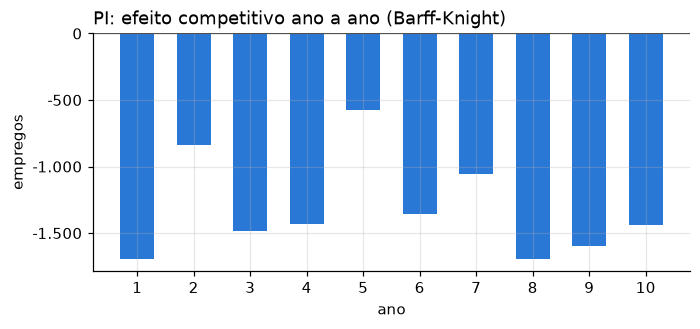

Pontos idênticos aos de Berzeg: True


,Pearson,Spearman,nRMSE,acerto de sinal
Barff-Knight (dinâmico),"0,984","0,985","0,244","1,000"


In [14]:
bk = M.dynamic_shift_share(E, regions)
display(foco(bk, PARES_DUNN))

# Contribuição anual do competitivo para o estado em foco
anual = []
for t in range(T):
    Et, Et1 = E[:, :, t], E[:, :, t + 1]
    git = M._rates(Et, Et1)[r_foco]
    gnit = Et1.sum(0) / Et.sum(0) - 1
    anual.append((Et[r_foco] * (git - gnit)).sum())
anual = pd.Series(anual, index=pd.Index(range(1, T + 1), name="ano"), name="CE anual")
print(f"Soma das contribuições anuais = {br(anual.sum(), 1)}")

fig, ax = plt.subplots(figsize=(7, 2.8))
ax.bar(anual.index, anual.values, color=AZUL, width=0.6)
ax.axhline(0, color=TINTA, lw=0.8)
ax.set_title(f"{UF_FOCO}: efeito competitivo ano a ano (Barff-Knight)", loc="left")
ax.set_xlabel("ano")
ax.set_ylabel("empregos")
ax.set_xticks(anual.index)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: br(v, 0)))
plt.show()

print(
    "Pontos idênticos aos de Berzeg:",
    np.allclose(bk["competitive"], berzeg["competitive"]),
)
registrar(1988, "Barff-Knight (dinâmico)", "Dynamic (Barff-Knight)", bk)

O competitivo dinâmico é numericamente idêntico ao de Berzeg: o modelo ANOVA é
a contraparte estocástica da identidade anual (o resultado de Knudsen e Barff, 1991).
A diferença é que Berzeg acrescenta o erro-padrão.

## 7. Esteban-Marquillas dinâmico

A combinação natural das seções 3 e 6: o homotético é recalculado a cada ano e os
dois termos são somados no tempo,

$$
CE^*_r = \sum_{t}\sum_i \hat E^t_{ri}\left(g^t_{ri}-g^t_i\right),\qquad
AE_r = \sum_{t}\sum_i \left(E^t_{ri}-\hat E^t_{ri}\right)\left(g^t_{ri}-g^t_i\right),
\qquad \hat E^t_{ri} = E^t_{r\cdot}\,\frac{E^t_{\cdot i}}{E^t_{\cdot\cdot}} .
$$

In [15]:
dem = M.dynamic_em(E, regions)
display(
    foco(
        dem,
        {
            "nacional": ("national", "true_national"),
            "estrutural": ("mix", "true_mix"),
            "competitivo homotético": ("competitive", "true_comp_homothetic"),
            "alocação": ("allocation", "true_alloc"),
            "total explicado": ("total_explained", "delta_E"),
        },
    )
)
registrar(
    1988,
    "Esteban-Marquillas dinâmico",
    "Dynamic Esteban-Marquillas",
    dem,
    alvo="true_comp_homothetic",
)

,estimado,verdadeiro,erro
nacional,"29.054,6","26.969,2","2.085,5"
estrutural,"3.339,3","2.373,6","965,7"
competitivo homotético,"-13.150,8","-12.464,5","-686,3"
alocação,"-20,9","760,4","-781,3"
total explicado,"19.222,2","19.222,2","-0,0"


,Pearson,Spearman,nRMSE,acerto de sinal
Esteban-Marquillas dinâmico,"0,985","0,978","0,237","1,000"


## 8. Regressão análoga completa (Buck e Atkins, 1976; Patterson, 1991)

A versão econométrica mais completa estima todos os efeitos de uma vez, por mínimos
quadrados ponderados (pesos $E_{rit}$) com efeitos fixos de ano, setor e região:

$$
g_{rit} = \alpha + \tau_t + \mu_i + \rho_r + u_{rit},
\qquad \sum_r w_r\,\rho_r = 0,\quad w_r = \sum_{i,t} E_{rit}.
$$

O efeito de região $\hat\rho_r$, recentrado para ter média ponderada zero, é a
taxa competitiva, com erro-padrão e estatística $t$ da regressão. Em empregos,
$CE_r = \hat\rho_r\,w_r$.

*Nota técnica:* o código inclui a constante e todas as dummies de ano, então a
matriz de desenho tem posto incompleto e o `statsmodels` emite um aviso
(`SingularMatrixWarning`). A colinearidade envolve apenas constante e anos; os
contrastes entre regiões continuam identificados. O erro-padrão da região de
referência é aproximado pela mediana dos demais.

In [16]:
import statsmodels.api  # noqa: F401  (importado antes, para o filtro de aviso valer)
from statsmodels.tools.sm_exceptions import SingularMatrixWarning

with warnings.catch_warnings():
    warnings.simplefilter("ignore", SingularMatrixWarning)
    far, far_res = M.full_analogue_regression(E, regions, sectors)
display(foco(far, {"competitivo": ("competitive", "true_comp")}))
f = far.set_index("region").loc[UF_FOCO]
print(
    f"{UF_FOCO}: ρ̂ = {br(f['comp_rate'], 4)} ao ano, se = {br(f['comp_rate_se'], 4)}, "
    f"t = {br(f['comp_t'], 2)};  R² da regressão = {br(far_res.rsquared)}"
)
display(
    significance_diagnostics({"Análoga completa": far}, data)
    .rename(columns=SIGNIF)
    .set_index("modelo")
)
registrar(1991, "Regressão análoga completa", "Full-analogue regression", far)

,estimado,verdadeiro,erro
competitivo,"-12.694,4","-11.704,1","-990,4"


PI: ρ̂ = -0,0098 ao ano, se = 0,0023, t = -4,25;  R² da regressão = 0,791


,% sinalizadas (terço forte),% sinalizadas (terço fraco),% sinalizadas (total)
modelo,,,
Análoga completa,"1,000","0,333","0,741"


,Pearson,Spearman,nRMSE,acerto de sinal
Regressão análoga completa,"0,985","0,984","0,233","1,000"


Diferente de Berzeg, aqui o efeito regional é um único parâmetro constante no
tempo, estimado junto com os demais, o que bate com o processo gerador
($c_{ri}$ não varia com $t$). O modelo só entrega o competitivo, não decompõe
nacional e estrutural em empregos.

## 9. Nazara e Hewings (2004): o shift-share espacial

O último passo troca a referência do efeito competitivo: em vez de comparar o
estado só com o país, compara-o também com a sua vizinhança. Com a matriz de
contiguidade padronizada na linha, $W$, a taxa da vizinhança é

$$
\tilde g_{ri} = \sum_k w_{rk}\, g_{ki},
$$

e o competitivo de Dunn se divide em

$$
CE_r = \underbrace{\sum_i E^0_{ri}\left(\tilde g_{ri} - g_i\right)}_{\text{vizinhança: a vizinhança cresce mais que o país?}}
     + \underbrace{\sum_i E^0_{ri}\left(g_{ri} - \tilde g_{ri}\right)}_{\text{próprio líquido: o estado cresce mais que os vizinhos?}} .
$$

Nacional e estrutural seguem Dunn, então a soma continua fechando com $\Delta E_r$.

In [17]:
g_ri_todos = M._rates(E0, ET)
g_til = W @ g_ri_todos
viz = pd.DataFrame(
    {
        "g_ri (estado)": g_ri_todos[r_foco],
        "g̃_ri (vizinhança)": g_til[r_foco],
        "g_i (país)": g_i,
    },
    index=sectors,
)
viz = viz.join(
    pd.DataFrame(
        g_ri_todos[[regions.index(v) for v in ADJACENCY[UF_FOCO]]].T,
        index=sectors,
        columns=ADJACENCY[UF_FOCO],
    )
)
print(f"Vizinhos de {UF_FOCO}, cada um com peso 1/{len(ADJACENCY[UF_FOCO])}:")
display(viz.style.format(decimal=",", thousands=".", formatter="{:.4f}"))

nh = M.nazara_hewings(E, regions, W)
PARES_NH = {
    "nacional": ("national", "true_national"),
    "estrutural": ("mix", "true_mix"),
    "vizinhança": ("neighborhood", "true_neigh"),
    "próprio líquido": ("own_net", "true_own_net"),
    "competitivo (soma)": ("competitive", "true_comp"),
    "total explicado": ("total_explained", "delta_E"),
}
display(foco(nh, PARES_NH))
print("Recuperação das partes espaciais (27 UFs):")
display(
    pd.DataFrame(
        {
            "vizinhança": score(nh, truth, "neighborhood", "true_neigh"),
            "próprio líquido": score(nh, truth, "own_net", "true_own_net"),
        }
    ).T.rename(columns=ROTULOS)
)
registrar(2004, "Nazara-Hewings (espacial)", "Nazara-Hewings spatial (static)", nh)

Vizinhos de PI, cada um com peso 1/5:


,g_ri (estado),g̃_ri (vizinhança),g_i (país),MA,CE,PE,BA,TO
Agro,"0,1139","0,1599","0,2887","0,3216","-0,0779","0,0853","0,2047","0,2659"
Industry,"0,0892","0,1394","0,3310","0,4851","0,0767","-0,0302","0,0880","0,0773"
Construction,"-0,0079","0,0408","0,0757","0,3887","-0,2273","-0,1768","0,1446","0,0751"
Commerce,"0,3617","0,2037","0,3924","0,2936","-0,1231","0,1790","0,2974","0,3717"
Services,"0,0664","0,1393","0,2024","-0,0002","-0,1568","0,1799","0,2027","0,4710"


,estimado,verdadeiro,erro
nacional,"30.020,9","26.969,2","3.051,8"
estrutural,"3.751,8","2.373,6","1.378,2"
vizinhança,"-16.036,1","-13.482,5","-2.553,5"
próprio líquido,"1.485,6","1.778,4","-292,8"
competitivo (soma),"-14.550,4","-11.704,1","-2.846,4"
total explicado,"19.222,2","19.222,2","-0,0"


Recuperação das partes espaciais (27 UFs):


,Pearson,Spearman,nRMSE,acerto de sinal
vizinhança,"0,987","0,987","0,241","0,926"
próprio líquido,"0,991","0,987","0,152","0,889"


,Pearson,Spearman,nRMSE,acerto de sinal
Nazara-Hewings (espacial),"0,985","0,985","0,231","1,000"


O competitivo total é o mesmo de Dunn, como a aditividade exige, por isso a nota
geral repete a da seção 1. O ganho está na divisão: o competitivo negativo do
estado em foco vem quase todo da vizinhança, que cresce menos que o país; em
relação aos próprios vizinhos ele está ligeiramente acima.

## 10. Nazara-Hewings dinâmico

Por fim, a decomposição espacial calculada ano a ano, à la Barff-Knight:

$$
NEIGH_r = \sum_t\sum_i E^t_{ri}\left(\tilde g^t_{ri}-g^t_i\right),\qquad
OWN_r = \sum_t\sum_i E^t_{ri}\left(g^t_{ri}-\tilde g^t_{ri}\right),
\qquad \tilde g^t_{ri} = \sum_k w_{rk}\,g^t_{ki}.
$$

In [18]:
nhd = M.dynamic_nazara_hewings(E, regions, W)
display(foco(nhd, PARES_NH))
display(
    pd.DataFrame(
        {
            "vizinhança": score(nhd, truth, "neighborhood", "true_neigh"),
            "próprio líquido": score(nhd, truth, "own_net", "true_own_net"),
        }
    ).T.rename(columns=ROTULOS)
)
registrar(2004, "Nazara-Hewings dinâmico", "Nazara-Hewings spatial (dynamic)", nhd)

,estimado,verdadeiro,erro
nacional,"29.054,6","26.969,2","2.085,5"
estrutural,"3.339,3","2.373,6","965,7"
vizinhança,"-16.007,0","-13.482,5","-2.524,5"
próprio líquido,"2.835,4","1.778,4","1.056,9"
competitivo (soma),"-13.171,7","-11.704,1","-1.467,6"
total explicado,"19.222,2","19.222,2","-0,0"


,Pearson,Spearman,nRMSE,acerto de sinal
vizinhança,"0,973","0,963","0,331","0,926"
próprio líquido,"0,992","0,982","0,129","0,926"


,Pearson,Spearman,nRMSE,acerto de sinal
Nazara-Hewings dinâmico,"0,984","0,985","0,244","1,000"


## 11. Síntese: o placar da semente fixa e o Monte Carlo

O placar abaixo reúne a nota de cada seção, em ordem cronológica de publicação.

In [19]:
tab = (
    pd.DataFrame(placar.values())
    .sort_values("ano", kind="stable")
    .reset_index(drop=True)
)
(
    tab[
        [
            "ano",
            "método",
            "pearson",
            "spearman",
            "nrmse",
            "sign_acc",
            "mix_nrmse",
            f"competitivo_{UF_FOCO}",
            f"verdade_{UF_FOCO}",
        ]
    ]
    .rename(
        columns={
            **ROTULOS,
            "mix_nrmse": "nRMSE estrutural",
            f"competitivo_{UF_FOCO}": f"competitivo {UF_FOCO}",
            f"verdade_{UF_FOCO}": f"verdade {UF_FOCO}",
        }
    )
    .style.hide(axis="index")
    .format(
        decimal=",",
        thousands=".",
        na_rep="—",
        formatter={
            "ano": str,
            "Pearson": "{:.3f}",
            "Spearman": "{:.3f}",
            "nRMSE": "{:.3f}",
            "acerto de sinal": "{:.2f}",
            "nRMSE estrutural": "{:.3f}",
            f"competitivo {UF_FOCO}": "{:,.0f}",
            f"verdade {UF_FOCO}": "{:,.0f}",
        },
    )
)

ano,método,Pearson,Spearman,nRMSE,acerto de sinal,nRMSE estrutural,competitivo PI,verdade PI
1959,"Dunn, pesos médios (Fuchs)","0,991","0,980","0,161","1,00","0,599",-13.691,-11.704
1960,Dunn clássico (pesos base),"0,985","0,985","0,231","1,00","0,413",-14.550,-11.704
1969,"Dunn, pesos terminais (Stilwell)","0,988","0,980","0,154","1,00","0,972",-12.832,-11.704
1972,Esteban-Marquillas,"0,988","0,979","0,201","1,00","0,413",-14.014,-12.465
1978,Berzeg (ANOVA),"0,984","0,985","0,244","1,00","0,341",-13.172,-11.704
1984,Arcelus (Modelo I),"0,988","0,979","0,201","1,00","0,413",-14.014,-12.465
1988,Barff-Knight (dinâmico),"0,984","0,985","0,244","1,00","0,341",-13.172,-11.704
1988,Esteban-Marquillas dinâmico,"0,985","0,978","0,237","1,00","0,341",-13.151,-12.465
1991,Regressão análoga completa,"0,985","0,984","0,233","1,00",—,-12.694,-11.704
2004,Nazara-Hewings (espacial),"0,985","0,985","0,231","1,00","0,413",-14.550,-11.704


Uma semente é uma única realização do ruído. Para saber se as diferenças são
sistemáticas, o gráfico compara o nRMSE desta semente com a média de 50 sementes
do Monte Carlo de `run_comparison.py` (arquivo `results_montecarlo.csv`) nos
cenários *benigno* e *estresse* (ciclo nacional volátil, choques setoriais fortes,
mais ruído).

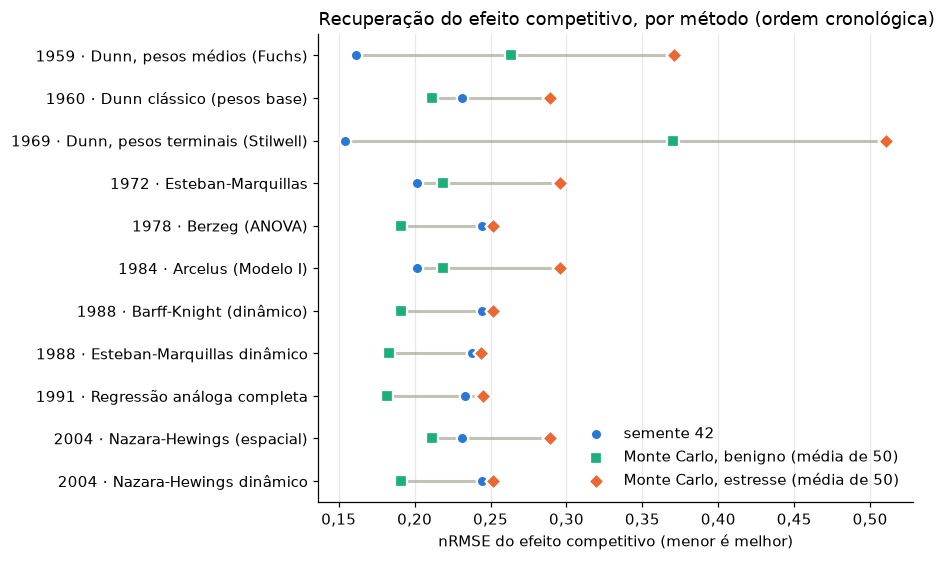

In [20]:
mc = pd.read_csv("results_montecarlo.csv")
mc_nrmse = mc.pivot(index="model", columns="scenario", values="nrmse_mean")
tab["MC benigno"] = tab["modelo_mc"].map(mc_nrmse["benign"])
tab["MC estresse"] = tab["modelo_mc"].map(mc_nrmse["stress"])

rot = [f"{a} · {m}" for a, m in zip(tab["ano"], tab["método"])]
y = np.arange(len(tab))[::-1]
fig, ax = plt.subplots(figsize=(8.5, 5.2))
trio = tab[["nrmse", "MC benigno", "MC estresse"]]
ax.hlines(y, trio.min(axis=1), trio.max(axis=1), color="#c3c2b7", lw=2, zorder=1)
ax.scatter(
    tab["nrmse"],
    y,
    s=55,
    color=AZUL,
    label=f"semente {SEED}",
    zorder=3,
    edgecolor="white",
    linewidth=1.5,
)
ax.scatter(
    tab["MC benigno"],
    y,
    s=55,
    color=AQUA,
    marker="s",
    zorder=3,
    label="Monte Carlo, benigno (média de 50)",
    edgecolor="white",
    linewidth=1.5,
)
ax.scatter(
    tab["MC estresse"],
    y,
    s=55,
    color=LARANJA,
    marker="D",
    zorder=3,
    label="Monte Carlo, estresse (média de 50)",
    edgecolor="white",
    linewidth=1.5,
)
ax.set_yticks(y, rot)
ax.set_xlabel("nRMSE do efeito competitivo (menor é melhor)")
ax.set_title(
    "Recuperação do efeito competitivo, por método (ordem cronológica)", loc="left"
)
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right", frameon=False)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: br(v, 2)))
plt.tight_layout()
plt.show()

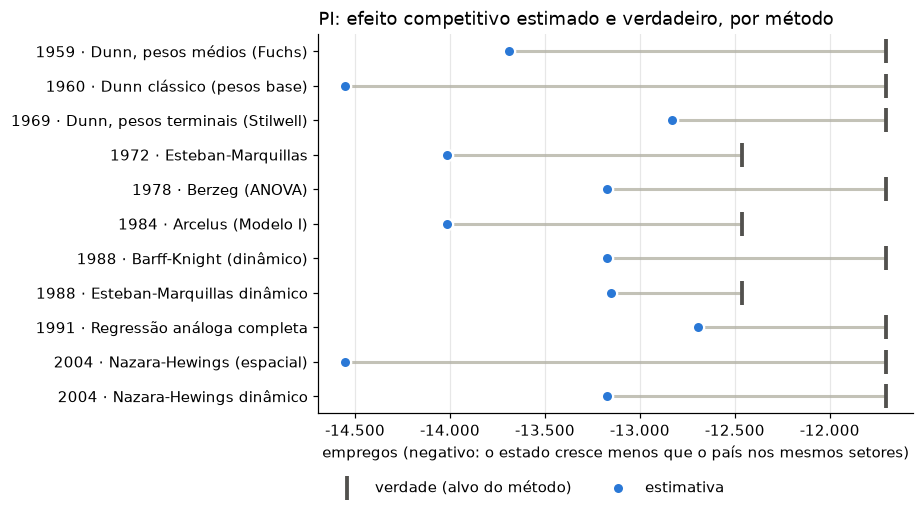

In [21]:
est, alvo = tab[f"competitivo_{UF_FOCO}"], tab[f"verdade_{UF_FOCO}"]
fig, ax = plt.subplots(figsize=(8.5, 4.8))
ax.hlines(
    y, np.minimum(est, alvo), np.maximum(est, alvo), color="#c3c2b7", lw=2, zorder=1
)
ax.scatter(
    alvo,
    y,
    marker="|",
    s=250,
    color=TINTA,
    linewidths=2.5,
    zorder=2,
    label="verdade (alvo do método)",
)
ax.scatter(
    est,
    y,
    s=55,
    color=AZUL,
    edgecolor="white",
    linewidth=1.5,
    zorder=3,
    label="estimativa",
)
ax.set_yticks(y, rot)
ax.set_xlabel(
    "empregos (negativo: o estado cresce menos que o país nos mesmos setores)"
)
ax.set_title(
    f"{UF_FOCO}: efeito competitivo estimado e verdadeiro, por método", loc="left"
)
ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: br(v, 0)))
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.14), ncol=2, frameon=False)
plt.tight_layout()
plt.show()

### O que a evolução mostra

Todos os métodos ordenam os estados quase da mesma forma. Nesta semente, a
correlação de Pearson com a verdade fica entre 0,98 e 0,99 e o sinal do
competitivo é acertado em todas as UFs, de modo que as críticas sucessivas não
mudam o diagnóstico qualitativo. Knudsen e Barff (1991) chegam à mesma conclusão.

As diferenças aparecem na magnitude do efeito, e uma semente só não basta para
ordená-las. Com `SEED = 42`, os pesos terminais e médios têm o menor nRMSE no
competitivo, à custa de um efeito estrutural bem pior e de um total que não fecha
com $\Delta E$. Na média de 50 sementes a ordem se inverte: os métodos que usam
todos os anos (Barff-Knight, E-M dinâmico, Berzeg e a regressão análoga completa)
ficam à frente, os pesos terminais ficam por último e a distância cresce no
cenário de estresse.

Cada geração de métodos acrescentou um tipo de resultado. Esteban-Marquillas
trouxe o efeito alocação, que separa os grupos do processo gerador como
prometido; o Modelo I de Arcelus, na forma implementada, coincide com ele.
Berzeg reproduz exatamente os números de Barff-Knight e acrescenta erros-padrão,
e a regressão análoga completa também entrega estatísticas $t$. Nazara-Hewings
divide o competitivo em vizinhança e desempenho próprio, e as duas partes são bem
recuperadas quando há dependência espacial ($\rho = 0{,}5$).

Os limites descritos no fim da seção 0 valem para todas essas conclusões.